# 02 · Preprocesamiento: de la radiografía DICOM al tensor que ve el modelo

**Proyecto:** Copiloto de triaje para neumonía en adultos · Proyecto Integrador, Maestría en Inteligencia Artificial (UEES), 2026.
**Cuaderno 2 de 5** (`01_exploracion` · `02_preprocesamiento` · `03_modelado` · `04_optimizacion` · `05_evaluacion`).

## Qué hace este cuaderno

Muestra **cómo se preparan los datos**, de principio a fin, **llamando a las funciones reales del paquete** `src/copiloto_triaje/` sobre archivos de RSNA. No reimplementa nada: lo que se ejecuta aquí es lo que ejecutaron `scripts/preparar_datos.py` y el entrenamiento.

```
DICOM (.dcm) ──leer_dicom──▶ píxeles uint8 + metadatos ──convertir_a_png──▶ PNG de 8 bits
metadatos + etiquetas ──construir_registros──▶ filtrar_por_edad (18-100) ──particionar_por_paciente (70/15/15, semilla 42)──▶ manifiestos train / val / test
PNG + manifiesto ──DatasetRadiografias──▶ Resize 320 ─▶ [aumento, solo en train] ─▶ ToTensor ─▶ Normalize (ImageNet) ──▶ tensor 3×320×320
```

## Qué NO hay en las salidas de este cuaderno

Los datos son de la competición **RSNA Pneumonia Detection Challenge** (Kaggle, 2018), y sus reglas **no permiten redistribuirlos**: el repositorio solo los referencia. Por eso las salidas guardadas son **formas, estadísticas y agregados**; no hay ninguna placa de RSNA ni una tabla con una fila por paciente. La única imagen que se dibuja es sintética y se rotula como tal.

## Cómo ejecutarlo

Hace falta el conjunto preparado (`data/README.md` dice cómo descargarlo y prepararlo) y la variable de entorno `RSNA_RAIZ` apuntando a su raíz (la carpeta que contiene `crudo/`, `png/` y `manifiestos/`). Sin ella, el paquete se niega a adivinar una ruta.

In [1]:
import io
import random
import sys
import tempfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
import torch
import torchvision
from PIL import Image, ImageDraw

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def raiz_del_repositorio() -> Path:
    # Sube desde la carpeta de trabajo hasta encontrar pyproject.toml: sirve
    # abriendo el cuaderno desde la raíz o desde notebooks/.
    aqui = Path.cwd().resolve()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "pyproject.toml").is_file() and (carpeta / "src" / "copiloto_triaje").is_dir():
            return carpeta
    raise SystemExit("Abre el cuaderno dentro del repositorio: no se encontró pyproject.toml.")


REPO = raiz_del_repositorio()
for carpeta in ("src", "scripts", "app"):
    sys.path.insert(0, str(REPO / carpeta))

from copiloto_triaje.config import Config, raiz_rsna  # noqa: E402

RAIZ = raiz_rsna()  # lee RSNA_RAIZ; no tiene valor por defecto a propósito
assert (RAIZ / "crudo" / "stage_2_train_images").is_dir(), "RSNA_RAIZ no apunta a un conjunto preparado"

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pydicom", pydicom.__version__)

Python 3.13.16 | numpy 2.5.2 | pandas 3.0.5
torch 2.14.0+cpu | torchvision 0.29.0+cpu | pydicom 3.0.2


## 1. La fuente

El conjunto preparado tiene cuatro carpetas que importan aquí:

| Carpeta | Contenido | Quién la escribe |
| :--- | :--- | :--- |
| `crudo/` | los 26 684 DICOM originales (`stage_2_train_images/`) y las etiquetas (`stage_2_train_labels.csv`) | la descarga de Kaggle |
| `png/` | un PNG de 8 bits por DICOM | `convertir_lote` (vía `scripts/preparar_datos.py`) |
| `manifiestos/` | `train.csv`, `val.csv`, `test.csv`: la partición, como artefacto explícito | `particionar_por_paciente` + `escribir_manifiestos` |
| `corridas/` | los reportes y pesos de cada corrida de entrenamiento (se usan en el cuaderno 04) | el entrenamiento |

In [2]:
dicom = sorted((RAIZ / "crudo" / "stage_2_train_images").glob("*.dcm"))
print(f"{len(dicom):,} DICOM en crudo/stage_2_train_images")
print(f"{len(list((RAIZ / 'png').glob('*.png'))):,} PNG en png/")
print("manifiestos:", sorted(p.name for p in (RAIZ / "manifiestos").glob("*.csv")))

26,684 DICOM en crudo/stage_2_train_images


26,684 PNG en png/
manifiestos: ['test.csv', 'train.csv', 'val.csv']


## 2. DICOM → píxeles y metadatos (`leer_dicom`)

`leer_dicom` devuelve los píxeles y los metadatos que usa el proyecto (`CAMPOS`: identificador, edad, sexo y vista de la placa, más el tamaño). Se aplica a una **muestra de 40 archivos elegidos con semilla 42** y solo se resumen en agregados.

El módulo `dicom.py` afirma, tras verificarlo el 16-sep-2026, que los DICOM de RSNA vienen en `uint8` con interpretación fotométrica `MONOCHROME2`, de modo que la conversión es directa. Aquí se comprueba sobre la muestra, en lugar de creerlo.

In [3]:
from copiloto_triaje.datos.dicom import CAMPOS, leer_dicom

muestra = random.Random(42).sample(dicom, 40)

tipos, formas, fotometria, bits = Counter(), Counter(), Counter(), Counter()
vistas, sexos, edades, metas = Counter(), Counter(), [], []
minimos, maximos, medias = [], [], []
for ruta in muestra:
    pixeles, meta = leer_dicom(ruta)
    cabecera = pydicom.dcmread(ruta, stop_before_pixels=True)
    metas.append(meta)
    tipos[str(pixeles.dtype)] += 1
    formas[pixeles.shape] += 1
    fotometria[str(cabecera.PhotometricInterpretation)] += 1
    bits[int(cabecera.BitsAllocated)] += 1
    vistas[meta["vista"]] += 1
    sexos[meta["sexo"]] += 1
    edades.append(int(meta["edad"]))
    minimos.append(int(pixeles.min())); maximos.append(int(pixeles.max())); medias.append(float(pixeles.mean()))

print("campos que extrae el paquete:", ", ".join(CAMPOS), "+ filas, columnas")
print("tipo de los píxeles ......", dict(tipos))
print("bits asignados ...........", dict(bits))
print("fotometría ...............", dict(fotometria))
print("formas ...................", {f"{a}×{b}": n for (a, b), n in formas.items()})
print(f"intensidad: mínimo {min(minimos)}, máximo {max(maximos)}, media de las medias {np.mean(medias):.1f}")
print("vista ....................", dict(vistas), "| sexo", dict(sexos))
print(f"edad: mediana {np.median(edades):.0f}, rango {min(edades)}-{max(edades)}")

campos que extrae el paquete: patientId, edad, sexo, vista + filas, columnas
tipo de los píxeles ...... {'uint8': 40}
bits asignados ........... {8: 40}
fotometría ............... {'MONOCHROME2': 40}
formas ................... {'1024×1024': 40}
intensidad: mínimo 0, máximo 255, media de las medias 124.5
vista .................... {'AP': 21, 'PA': 19} | sexo {'F': 18, 'M': 22}
edad: mediana 49, rango 12-83


**Lectura.** La muestra se saca de los 26 684 DICOM **sin filtrar por edad** (el filtro llega en la sección 6), por eso su rango de edades baja de 18. En la muestra, todos los píxeles son `uint8`, `MONOCHROME2` y de 1 024 × 1 024: no hay profundidades de bits distintas que reescalar. Es la propiedad que permite que `convertir_a_png` sea directa; el reescalado min-max que lleva como red de seguridad no se activa con estas placas.

La **vista** (PA, de pie; AP, portátil) viaja con la placa porque, como mostró la exploración (cuaderno 01), **predice la etiqueta**: es el sesgo más importante del conjunto y el preprocesamiento no lo corrige (sección 10).

## 3. La regla de lo que el motor puede evaluar (`comprobar_que_se_puede_evaluar`)

El modelo se entrenó con las placas de RSNA: 8 bits sin signo, `MONOCHROME2`, una muestra por píxel y un solo cuadro. Una placa distinta daría una cifra que no vale (según lo medido en SP5-B4, una neumonía en 16 bits baja de 0,91 a 0,48). Por eso el servidor y la app aplican esta regla **antes de descodificar un solo píxel**; el entrenamiento y la exploración no la necesitan.

Se comprueba que las 40 placas de la muestra pasan, y se muestra qué dice la regla de unas variantes fabricadas **en memoria** cambiando una sola etiqueta de la cabecera (no se escribe nada en disco).

In [4]:
from copiloto_triaje.datos.dicom import PlacaNoEvaluable, comprobar_que_se_puede_evaluar

aceptadas = 0
for ruta in muestra:
    comprobar_que_se_puede_evaluar(ruta.read_bytes())
    aceptadas += 1
print(f"{aceptadas} de {len(muestra)} placas de la muestra se pueden evaluar\n")


def con_cabecera_cambiada(ruta, **cambios) -> bytes:
    ds = pydicom.dcmread(ruta)
    for etiqueta, valor in cambios.items():
        setattr(ds, etiqueta, valor)
    memoria = io.BytesIO()
    ds.save_as(memoria)
    return memoria.getvalue()


variantes = {
    "escala de grises invertida": {"PhotometricInterpretation": "MONOCHROME1"},
    "16 bits": {"BitsAllocated": 16, "BitsStored": 16, "HighBit": 15},
    "lado de 6 000 píxeles": {"Rows": 6000},
    "tres cuadros": {"NumberOfFrames": 3},
}
for nombre, cambios in variantes.items():
    try:
        comprobar_que_se_puede_evaluar(con_cabecera_cambiada(muestra[0], **cambios))
        print(f"{nombre}: PASA (inesperado)")
    except PlacaNoEvaluable as rechazo:
        print(f"{nombre}\n    motivo = {rechazo.motivo!r}\n    {rechazo}")

40 de 40 placas de la muestra se pueden evaluar

escala de grises invertida
    motivo = 'fotometria'
    guarda la escala de grises invertida (en DICOM, MONOCHROME1), y el modelo solo evalúa placas MONOCHROME2, como las de RSNA con las que se entrenó.
16 bits
    motivo = 'bits'
    es de 16 bits, y el modelo solo evalúa placas de 8 bits sin signo, como las de RSNA con las que se entrenó.
lado de 6 000 píxeles
    motivo = 'tamano'
    declara 6000 × 1024 píxeles, y no se leen placas de más de 5000 de lado (una placa de tórax digital ronda los 4300 × 4300).
tres cuadros
    motivo = 'cuadros'
    el fichero trae 3 imágenes, y se evalúa una placa sola.


## 4. DICOM → PNG (`convertir_lote`)

`convertir_lote` convierte una lista de DICOM a PNG de 8 bits y tiene tres propiedades que importan en 26 684 archivos:

1. **Un archivo ilegible no aborta el proceso**: se omite y se registra (`omitidos`). Una pérdida silenciosa de datos sería peor que un fallo ruidoso.
2. **Escritura atómica**: se escribe a un temporal y luego `os.replace`, así que un corte a mitad no deja un PNG truncado con el nombre definitivo.
3. **Idempotente**: si el PNG ya existe *y se puede descodificar*, no lo reescribe.

Se convierten 12 de la muestra a una carpeta temporal, se compara píxel a píxel con los PNG de la caché del conjunto preparado y se repite la conversión para ver la idempotencia.

In [5]:
from copiloto_triaje.datos.dicom import convertir_lote

lote = muestra[:12]
with tempfile.TemporaryDirectory() as temporal:
    destino = Path(temporal)
    convertidos, omitidos = convertir_lote(lote, destino)
    print(f"convertidos: {len(convertidos)} | omitidos: {len(omitidos)}")

    modos, tamanos, kb = Counter(), Counter(), []
    iguales_a_dicom = iguales_a_cache = 0
    for ruta in lote:
        png = destino / f"{ruta.stem}.png"
        kb.append(png.stat().st_size / 1024)
        with Image.open(png) as imagen:
            modos[imagen.mode] += 1
            tamanos[imagen.size] += 1
            nuevo = np.asarray(imagen)
        iguales_a_dicom += int(np.array_equal(nuevo, leer_dicom(ruta)[0]))
        with Image.open(RAIZ / "png" / f"{ruta.stem}.png") as cache:
            iguales_a_cache += int(np.array_equal(nuevo, np.asarray(cache)))
    print("modo de los PNG:", dict(modos), "| tamaños:", {f"{a}×{b}": n for (a, b), n in tamanos.items()})
    kb_dicom = [r.stat().st_size / 1024 for r in lote]
    print(f"peso: PNG de {min(kb):.0f} a {max(kb):.0f} KB; DICOM de {min(kb_dicom):.0f} a {max(kb_dicom):.0f} KB")
    print(f"PNG idéntico a los píxeles del DICOM (conversión sin pérdida): {iguales_a_dicom} de {len(lote)}")
    print(f"PNG idéntico al de la caché del conjunto preparado: {iguales_a_cache} de {len(lote)}")

    antes = {p.name: p.stat().st_mtime_ns for p in destino.glob("*.png")}
    convertir_lote(lote, destino)
    despues = {p.name: p.stat().st_mtime_ns for p in destino.glob("*.png")}
    print("segunda pasada sin reescribir ningún PNG (idempotente):", antes == despues)

convertidos: 12 | omitidos: 0


modo de los PNG: {'L': 12} | tamaños: {'1024×1024': 12}
peso: PNG de 272 a 398 KB; DICOM de 88 a 155 KB
PNG idéntico a los píxeles del DICOM (conversión sin pérdida): 12 de 12
PNG idéntico al de la caché del conjunto preparado: 12 de 12


segunda pasada sin reescribir ningún PNG (idempotente): True


## 5. Etiquetas y registros (`cargar_etiquetas`, `construir_registros`)

El CSV de etiquetas trae **una fila por caja** de opacidad (y una fila sin caja por cada paciente sin opacidad). `cargar_etiquetas` lo colapsa a **un valor por paciente**: positivo si alguna de sus filas lo es. Después `construir_registros` une esa etiqueta con los metadatos de cada imagen y descarta lo que no tenga etiqueta.

Los metadatos de las 26 684 placas salen de `metadatos_eda.csv`, que escribe `scripts/extraer_metadatos.py` leyendo **solo las cabeceras** de los DICOM (`stop_before_pixels=True`: 26 segundos en vez de media hora). Antes de fiarse de él se comprueba contra la lectura directa de la muestra.

In [6]:
from copiloto_triaje.datos.preparacion import cargar_etiquetas, construir_registros

ruta_etiquetas = RAIZ / "crudo" / "stage_2_train_labels.csv"
filas = pd.read_csv(ruta_etiquetas)
etiquetas = cargar_etiquetas(ruta_etiquetas)
positivos = sum(etiquetas.values())
print(f"{len(filas):,} filas del CSV ({int(filas['Target'].sum()):,} con caja) -> {len(etiquetas):,} pacientes")
print(f"positivos: {positivos:,} ({positivos / len(etiquetas):.2%}) | negativos: {len(etiquetas) - positivos:,}")

# edad como texto, tal como la entrega el DICOM: edad_en_anios la interpreta
tabla = pd.read_csv(RAIZ / "metadatos_eda.csv", dtype={"edad": str})
por_paciente = tabla.set_index("patientId")
coinciden = sum(
    (m["edad"], m["sexo"], m["vista"]) == tuple(por_paciente.loc[m["patientId"], ["edad", "sexo", "vista"]])
    for m in metas)
print(f"metadatos del CSV iguales a la lectura directa del DICOM: {coinciden} de {len(metas)}")

metadatos = tabla[["patientId", "edad", "sexo", "vista", "filas", "columnas"]].to_dict("records")
registros = construir_registros(metadatos, etiquetas)
print(f"registros con etiqueta: {len(registros):,} de {len(metadatos):,}")

30,227 filas del CSV (9,555 con caja) -> 26,684 pacientes
positivos: 6,012 (22.53%) | negativos: 20,672


metadatos del CSV iguales a la lectura directa del DICOM: 40 de 40


registros con etiqueta: 26,684 de 26,684


## 6. El filtro de edad (`filtrar_por_edad`)

El alcance entregado en la Semana 1 declara **adultos**, y la exploración (cuaderno 01) encontró que una parte del padrón son menores de 18 años y que hay cinco edades imposibles. Entrenar con ellos contradiría el alcance, y la neumonía pediátrica se ve distinta en la placa (`docs/mejoras-2026-09-21.md`, §4.1). `filtrar_por_edad` deja **18 a 100 años** y devuelve un resumen de cuántos descartó y por qué, para que la pérdida de datos nunca sea silenciosa.

In [7]:
from copiloto_triaje.datos.preparacion import filtrar_por_edad

cfg = Config(raiz_datos=RAIZ, zip_rsna=RAIZ)  # solo para leer los parámetros por defecto
aceptados, resumen = filtrar_por_edad(registros, cfg.edad_minima, cfg.edad_maxima)
print(f"rango {resumen['rango']}: entraron {resumen['entraron']:,}, aceptados {resumen['aceptados']:,}, "
      f"descartados {resumen['descartados']:,}")
print("por motivo:", resumen["por_motivo"])

positivos_antes = sum(r["etiqueta"] for r in registros) / len(registros)
positivos_despues = sum(r["etiqueta"] for r in aceptados) / len(aceptados)
ids_menores = {d["patientId"] for d in resumen["detalle"] if d["motivo"].startswith("menor")}
tasa_menores = np.mean([etiquetas[i] for i in ids_menores])
print(f"positivos: {positivos_antes:.2%} antes del filtro -> {positivos_despues:.2%} después "
      f"(entre los menores descartados: {tasa_menores:.1%})")

rango [18, 100]: entraron 26,684, aceptados 25,403, descartados 1,281
por motivo: {'menor de 18': 1276, 'mayor de 100 (implausible)': 5}
positivos: 22.53% antes del filtro -> 22.15% después (entre los menores descartados: 30.2%)


## 7. La partición por paciente (`particionar_por_paciente`) y la verificación de fuga

Un mismo paciente nunca puede estar en dos conjuntos: si ocurre, el modelo se evalúa con datos que ya vio y las métricas dejan de significar nada (es el error documentado que invalida al conjunto pediátrico de Kermany). La partición es **70 / 15 / 15**, **estratificada por la etiqueta del paciente** y con la **semilla 42** que declara `Config`; `verificar_sin_fuga` lanza `FugaDeDatos` si algún `patientId` aparece en dos conjuntos.

Se hacen tres comprobaciones: que la partición recalculada **reproduce exactamente los manifiestos** que usó el entrenamiento, que no hay fuga y que `verificar_sin_fuga` **de verdad detecta una** (con una fuga fabricada).

In [8]:
from copiloto_triaje.datos.particion import FugaDeDatos, particionar_por_paciente, verificar_sin_fuga

particiones = particionar_por_paciente(aceptados, cfg.proporciones, cfg.semilla)
verificar_sin_fuga(particiones)
print(f"proporciones {cfg.proporciones}, semilla {cfg.semilla}: sin fuga entre train, val y test")

resumen_particion = []
for nombre in ("train", "val", "test"):
    manifiesto = pd.read_csv(RAIZ / "manifiestos" / f"{nombre}.csv")
    idem = {r["patientId"] for r in particiones[nombre]} == set(manifiesto["patientId"])
    n = len(particiones[nombre])
    pos = sum(r["etiqueta"] for r in particiones[nombre])
    resumen_particion.append({"conjunto": nombre, "imágenes": n, "positivos": pos,
                              "prevalencia": round(pos / n, 4), "igual al manifiesto": idem})
print(pd.DataFrame(resumen_particion).to_string(index=False))

# Una fuga fabricada: una imagen de un paciente de train, copiada a test.
contaminadas = {k: list(v) for k, v in particiones.items()}
contaminadas["test"].append(dict(contaminadas["train"][0]))
try:
    verificar_sin_fuga(contaminadas)
    print("fuga fabricada: NO detectada (error)")
except FugaDeDatos as fuga:
    print("fuga fabricada detectada:", str(fuga).split(":")[0])

proporciones (0.7, 0.15, 0.15), semilla 42: sin fuga entre train, val y test


conjunto  imágenes  positivos  prevalencia  igual al manifiesto
   train     17782       3939       0.2215                 True
     val      3810        844       0.2215                 True
    test      3811        844       0.2215                 True
fuga fabricada detectada: 1 paciente(s) en 'test' y 'train' a la vez


Prevalencia de opacidad por vista y conjunto (agregados):
conjunto vista  placas  prevalencia
    test    AP    1724        0.372
    test    PA    2087        0.097
   train    AP    8043        0.377
   train    PA    9739        0.093
     val    AP    1692        0.392
     val    PA    2118        0.085


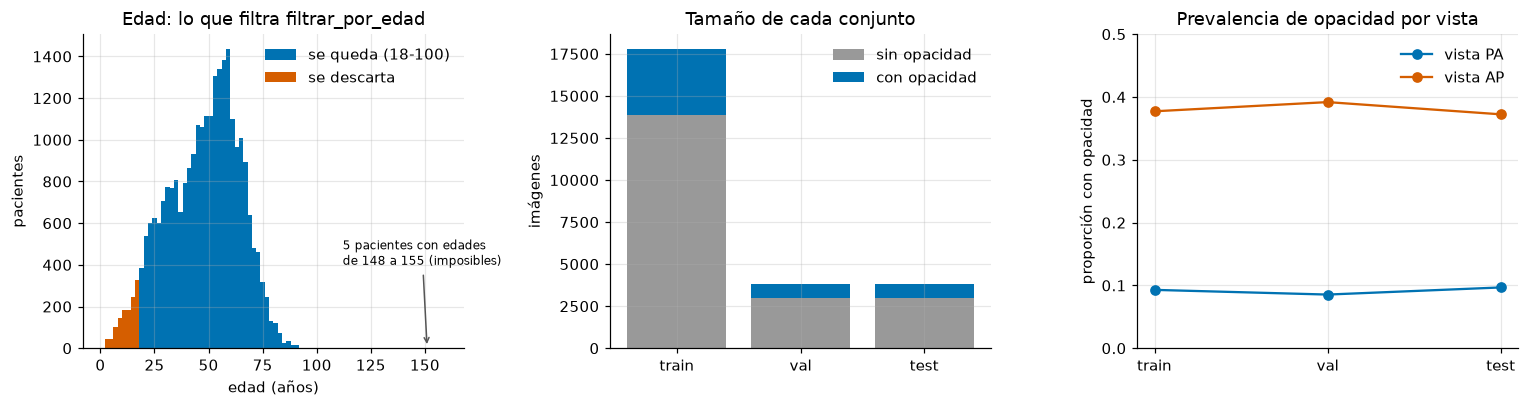

In [9]:
vistas_por_id = tabla.set_index("patientId")["vista"]
filas_vista = []
for nombre in ("train", "val", "test"):
    for r in particiones[nombre]:
        filas_vista.append({"conjunto": nombre, "vista": vistas_por_id[r["patientId"]], "etiqueta": r["etiqueta"]})
por_vista = pd.DataFrame(filas_vista).groupby(["conjunto", "vista"])["etiqueta"].agg(["size", "mean"]).reset_index()
print("Prevalencia de opacidad por vista y conjunto (agregados):")
print(por_vista.rename(columns={"size": "placas", "mean": "prevalencia"}).round(3).to_string(index=False))

edad_num = tabla["edad_num"]
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))

ejes[0].hist(edad_num[(edad_num >= 18) & (edad_num <= 100)], bins=np.arange(0, 162, 2), color="#0072B2", label="se queda (18-100)")
ejes[0].hist(edad_num[(edad_num < 18) | (edad_num > 100)], bins=np.arange(0, 162, 2), color="#D55E00", label="se descarta")
ejes[0].set(title="Edad: lo que filtra filtrar_por_edad", xlabel="edad (años)", ylabel="pacientes")
ejes[0].annotate("5 pacientes con edades\nde 148 a 155 (imposibles)", xy=(151, 5), xytext=(112, 400), fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="#555555"))
ejes[0].legend(frameon=False)

base = np.zeros(3)
for etiqueta, color, texto in ((0, "#999999", "sin opacidad"), (1, "#0072B2", "con opacidad")):
    valores = np.array([sum(1 for r in particiones[n] if r["etiqueta"] == etiqueta) for n in ("train", "val", "test")])
    ejes[1].bar(["train", "val", "test"], valores, bottom=base, color=color, label=texto)
    base += valores
ejes[1].set(title="Tamaño de cada conjunto", ylabel="imágenes")
ejes[1].legend(frameon=False)

for vista, color in (("PA", "#0072B2"), ("AP", "#D55E00")):
    sub = por_vista[por_vista["vista"] == vista].set_index("conjunto").loc[["train", "val", "test"]]
    ejes[2].plot(["train", "val", "test"], sub["mean"].to_numpy(), "o-", color=color, label=f"vista {vista}")
ejes[2].set(title="Prevalencia de opacidad por vista", ylabel="proporción con opacidad", ylim=(0, 0.5))
ejes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

**Lectura.** La partición recalculada con las funciones del paquete **reproduce los manifiestos del entrenamiento** y no tiene fuga; la comprobación se prueba a sí misma con una fuga fabricada. La prevalencia es casi igual en los tres conjuntos porque la estratificación se hace por la etiqueta del paciente.

Lo que la partición **no** equilibra es la **vista**: en los tres conjuntos las placas AP (portátiles) tienen una prevalencia de opacidad mucho mayor que las PA. Es el sesgo de confusión del conjunto, y reaparece en la evaluación (cuaderno 05).

## 8. Transformaciones (`construir_transformaciones`)

| Paso | En evaluación | En entrenamiento | Por qué |
| :--- | :---: | :---: | :--- |
| `Resize((320, 320))` | sí | sí | 320 px en vez de 224: las opacidades son sutiles y difusas, y reducir una placa de 1 024 a 224 tira la mayor parte de esa señal (`docs/mejoras-2026-09-21.md`, §4) |
| `RandomAffine(degrees=7, translate=(0.05, 0.05))` | no | sí | aumento de datos solo en entrenamiento, una de las defensas contra el sobreajuste (`docs/mejoras-2026-09-21.md`, §6) |
| `ColorJitter(brightness=0.15, contrast=0.15)` | no | sí | ídem |
| `ToTensor` + `Normalize(media, desviación de ImageNet)` | sí | sí | la red es de ImageNet; la placa de un canal se replica a 3 |
| volteo horizontal | **no** | **no** | la lateralidad cardíaca es información clínica real: voltearla produce anatomía imposible |

Una advertencia del propio código: `RandomAffine` y `ColorJitter` usan el generador global de torch (la API de torchvision no acepta uno propio), así que la reproducibilidad del aumento depende de sembrar `torch.manual_seed`.

In [10]:
from copiloto_triaje.datos.dataset import DESV_IMAGENET, MEDIA_IMAGENET, construir_transformaciones
from torchvision import transforms

evaluacion = construir_transformaciones(320, entrenamiento=False)
entrenamiento = construir_transformaciones(320, entrenamiento=True)
print("EVALUACIÓN:", evaluacion, "\n")
print("ENTRENAMIENTO:", entrenamiento, "\n")

with Image.open(RAIZ / "png" / f"{muestra[0].stem}.png") as imagen:
    rgb = imagen.convert("RGB")  # la red es de ImageNet: 3 canales
x = evaluacion(rgb)
sin_normalizar = transforms.Compose(evaluacion.transforms[:-1])(rgb)
print(f"forma {tuple(x.shape)}, tipo {x.dtype}")
print("antes de normalizar: canales iguales =", bool(torch.equal(sin_normalizar[0], sin_normalizar[1])
      and torch.equal(sin_normalizar[1], sin_normalizar[2])),
      f"| rango [{sin_normalizar.min():.3f}, {sin_normalizar.max():.3f}]")
print("rango posible tras normalizar, por canal:",
      [f"[{(0 - m) / s:.2f}, {(1 - m) / s:.2f}]" for m, s in zip(MEDIA_IMAGENET, DESV_IMAGENET)])

# Cuánto mueve el aumento los píxeles: 30 versiones aumentadas de la misma placa
# frente a la versión de evaluación (en unidades normalizadas). Solo números.
torch.manual_seed(42)
diferencias = [float((entrenamiento(rgb) - x).abs().mean()) for _ in range(30)]
print(f"diferencia absoluta media aumentada-evaluación: mediana {np.median(diferencias):.3f}, "
      f"percentil 95 {np.percentile(diferencias, 95):.3f}, máxima {max(diferencias):.3f}")

EVALUACIÓN: Compose(
    Resize(size=(320, 320), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
) 

ENTRENAMIENTO: Compose(
    Resize(size=(320, 320), interpolation=bilinear, max_size=None, antialias=True)
    RandomAffine(degrees=[-7.0, 7.0], translate=(0.05, 0.05))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
) 

forma (3, 320, 320), tipo torch.float32
antes de normalizar: canales iguales = True | rango [0.000, 0.882]
rango posible tras normalizar, por canal: ['[-2.12, 2.25]', '[-2.04, 2.43]', '[-1.80, 2.64]']


diferencia absoluta media aumentada-evaluación: mediana 0.379, percentil 95 0.641, máxima 0.694


Para **ver** lo que hace el aumento sin enseñar una placa de RSNA se usa una **imagen sintética** (un patrón de rejilla, un círculo y una «L» asimétrica) pasada por las mismas dos cadenas de transformaciones. No es una radiografía.

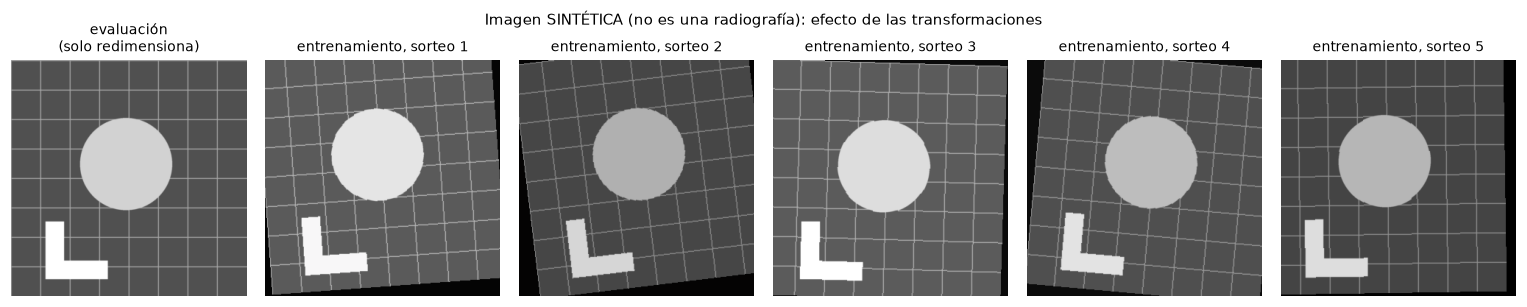

In [11]:
fantasma = Image.new("L", (1024, 1024), 80)
dibujo = ImageDraw.Draw(fantasma)
for k in range(0, 1024, 128):
    dibujo.line([(k, 0), (k, 1023)], fill=170, width=4)
    dibujo.line([(0, k), (1023, k)], fill=170, width=4)
dibujo.ellipse([300, 250, 700, 650], fill=210)
dibujo.rectangle([150, 700, 230, 950], fill=255)
dibujo.rectangle([150, 870, 420, 950], fill=255)
fantasma = fantasma.convert("RGB")

media = torch.tensor(MEDIA_IMAGENET).view(3, 1, 1)
desviacion = torch.tensor(DESV_IMAGENET).view(3, 1, 1)


def para_mostrar(tensor):
    return (tensor * desviacion + media).clamp(0, 1).permute(1, 2, 0).numpy()


fig, ejes = plt.subplots(1, 6, figsize=(14, 2.8))
ejes[0].imshow(para_mostrar(evaluacion(fantasma))); ejes[0].set_title("evaluación\n(solo redimensiona)", fontsize=9)
for k in range(1, 6):
    torch.manual_seed(100 + k)
    ejes[k].imshow(para_mostrar(entrenamiento(fantasma))); ejes[k].set_title(f"entrenamiento, sorteo {k}", fontsize=9)
for eje in ejes:
    eje.axis("off")
fig.suptitle("Imagen SINTÉTICA (no es una radiografía): efecto de las transformaciones", fontsize=10)
fig.tight_layout()
plt.show()

## 9. Del manifiesto al lote (`DatasetRadiografias`) y el peso de la clase positiva

`DatasetRadiografias` lee **siempre desde un manifiesto**, nunca de la carpeta: así la partición es un artefacto explícito y auditable. Devuelve `(tensor, etiqueta)`. Si un PNG está truncado, el error dice **cuál** y en qué fila del manifiesto, en vez de obligar a buscarlo entre 25 403.

El desbalance (22 % de positivos) se compensa en la pérdida: `entrenar()` usa `BCEWithLogitsLoss(pos_weight = negativos / positivos)`, calculado sobre **la partición de entrenamiento de cada corrida**. Ese cálculo vive dentro de `entrenar()`; aquí se repite la fórmula sobre el manifiesto, para ver el valor.

In [12]:
from copiloto_triaje.datos.dataset import DatasetRadiografias
from torch.utils.data import DataLoader

val = pd.read_csv(RAIZ / "manifiestos" / "val.csv")
conjunto = DatasetRadiografias(val.sample(48, random_state=42), RAIZ / "png", cfg.tam_imagen, entrenamiento=False)
x, y = next(iter(DataLoader(conjunto, batch_size=cfg.lote, num_workers=0)))
print(f"lote de validación: x {tuple(x.shape)} {x.dtype} | y {tuple(y.shape)} {y.dtype} | "
      f"positivos en el lote: {int(y.sum())} de {len(y)}")
print(f"tras normalizar: rango [{x.min():.2f}, {x.max():.2f}], media {x.mean():.2f}")

train = pd.read_csv(RAIZ / "manifiestos" / "train.csv")
positivos_train = float(train["etiqueta"].sum())
negativos_train = len(train) - positivos_train
peso = negativos_train / positivos_train
print(f"\nentrenamiento: {len(train):,} imágenes, {int(positivos_train):,} positivas "
      f"({positivos_train / len(train):.2%}) -> pos_weight = {peso:.3f}")
criterio = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor([peso]))
print("peso de la clase positiva en el criterio:", criterio.pos_weight.tolist())

lote de validación: x (24, 3, 320, 320) torch.float32 | y (24,) torch.float32 | positivos en el lote: 4 de 24
tras normalizar: rango [-2.12, 2.64], media 0.28

entrenamiento: 17,782 imágenes, 3,939 positivas (22.15%) -> pos_weight = 3.514
peso de la clase positiva en el criterio: [3.514343738555908]


## 10. Resumen de decisiones, y lo que el preprocesamiento NO hace

| Decisión | Dónde vive | Valor | Fuente |
| :--- | :--- | :--- | :--- |
| Qué se lee del DICOM | `datos/dicom.py` (`CAMPOS`) | id, edad, sexo, vista, filas, columnas | este cuaderno, §2 |
| Formato intermedio | `convertir_lote` | PNG de 8 bits, escritura atómica, idempotente | §4 |
| Qué placas evalúa el motor | `comprobar_que_se_puede_evaluar` | 8 bits sin signo, `MONOCHROME2`, un cuadro, ≤ 5 000 px de lado | §3; SP5-B4 |
| Población | `filtrar_por_edad` | adultos, 18-100 años | §6; `docs/mejoras-2026-09-21.md` §4.1 |
| Partición | `particionar_por_paciente` | 70/15/15 por paciente, estratificada por etiqueta, semilla 42 | §7 |
| Resolución | `construir_transformaciones` | 320 × 320 | §8; `docs/mejoras-2026-09-21.md` §4 |
| Aumento | `construir_transformaciones` | afín ±7° y 5 % de traslación; brillo y contraste 0,15; solo en train; sin volteo | §8 |
| Desbalance | `entrenar()` | `pos_weight = negativos / positivos` por corrida | §9 |

**Lo que no hace, y hay que decirlo:**

- **No corrige el sesgo de la vista.** AP y PA tienen prevalencias muy distintas en los tres conjuntos (§7) y el modelo puede aprovecharlo. La mitigación evaluada es un umbral por vista (cuaderno 04, apagado por defecto), no un cambio de los datos.
- **No normaliza el contraste placa a placa** (ni ecualización adaptativa): la red recibe la intensidad tal como viene del DICOM. En este proyecto no hay una medición de cuánto afectaría hacerlo.
- **La partición garantiza que un paciente no cruza de conjunto**, no que dos pacientes distintos no compartan una imagen casi idéntica: no se buscan duplicados.
- **La etiqueta es la de RSNA**: presencia de *opacidad pulmonar* según los lectores del reto, un sustituto de la neumonía y no un diagnóstico confirmado.
- **Baja la resolución** de 1 024 a 320 px. Se pasó de 224 a 320 px junto con otros cambios (cuaderno 04), de modo que su efecto aislado no se midió, y no se probó la resolución completa.